# Modeling 1 — Baseline theo recency

## Câu hỏi

Tại cutoff, quy tắc đơn giản chỉ dùng số ngày từ basket gần nhất dự báo được việc household phát sinh **bất kỳ basket trong 7 ngày tiếp theo** đến mức nào? Kết quả tạo mốc để so sánh Logistic Regression, LightGBM và các feature bổ sung.

Các nhóm đã được xác định trong EDA. Xác suất từng nhóm được tính **chỉ trên train**; validation dùng để đánh giá. Notebook không đọc test. Mỗi household có thể xuất hiện tại nhiều cutoff nên các dòng không độc lập.

## 1. Nạp dữ liệu và xác minh hợp đồng

Đọc đúng hai tập qua bộ kiểm tra đã xây dựng ở Data Preparation. `household_key`, `snapshot_day`, nhãn và các cờ kiểm tra không được dùng làm feature.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

ROOT = Path.cwd()
if ROOT.name == 'research' and ROOT.parent.name == 'notebooks': ROOT = ROOT.parent
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from propensity_v2.prepared_data import load_prepared_split

DATA = ROOT / 'artifacts' / 'data_preparation'
OUT = ROOT / 'artifacts' / 'research'/'baseline_recency'
train, feature_columns = load_prepared_split(DATA, 'train')
validation, validation_features = load_prepared_split(DATA, 'validation')
assert feature_columns == validation_features and 'recency_days' in feature_columns
assert train.snapshot_day.max() + 7 < validation.snapshot_day.min()
print(f'Train: {len(train):,} household-snapshot; validation: {len(validation):,}.')

Train: 129,834 household-snapshot; validation: 27,480.


## 2. Ước lượng xác suất theo nhóm recency

Các khoảng cố định là `0–7`, `8–14`, `15–30`, `31–60`, `61–90` và `91+` ngày. Xác suất của một nhóm là tỷ lệ target dương của các household-snapshot train thuộc nhóm đó; một household xuất hiện nhiều lần được tính nhiều lần. Nếu nhóm không có quan sát train, dùng tỷ lệ target chung của train và ghi rõ đây là fallback.

Tỷ lệ mua chung của train chỉ là thông tin tham chiếu; baseline chính là quy tắc theo recency.

In [2]:
TARGET = 'target_any_basket'
LABELS = ['0–7', '8–14', '15–30', '31–60', '61–90', '91+']
BINS = [-1, 7, 14, 30, 60, 90, np.inf]
def group_recency(values):
    if values.isna().any() or values.lt(0).any():
        raise ValueError('Recency phải hữu hạn và không âm')
    result = pd.cut(values, bins=BINS, labels=LABELS)
    if result.isna().any(): raise ValueError('Recency không thuộc nhóm nào')
    return result

train_group = group_recency(train.recency_days)
validation_group = group_recency(validation.recency_days)
global_rate = float(train[TARGET].mean())
rates = (train.assign(recency_group=train_group).groupby('recency_group', observed=False)
         .agg(household_snapshots=(TARGET,'size'), household_count=('household_key','nunique'),
              positive_snapshots=(TARGET,'sum'), purchase_rate=(TARGET,'mean')))
rates['fallback_to_train_rate'] = rates.household_snapshots.eq(0)
rates['prediction'] = rates.purchase_rate.fillna(global_rate)
assert rates.prediction.between(0,1).all()
validation = validation.copy()
validation['recency_group'] = validation_group
validation['probability'] = validation.recency_group.map(rates.prediction).astype(float)
assert validation.probability.notna().all()
print(f'Tỷ lệ mua chung train (tham chiếu): {global_rate:.2%}')
print('Nhóm dùng fallback:', int(rates.fallback_to_train_rate.sum()))
display(rates)

Tỷ lệ mua chung train (tham chiếu): 52.79%
Nhóm dùng fallback: 0


,household_snapshots,household_count,positive_snapshots,purchase_rate,fallback_to_train_rate,prediction
recency_group,,,,,,
0–7,73142,2464,51546,0.704739,False,0.704739
8–14,16994,2333,8334,0.490408,False,0.490408
15–30,15233,2031,5359,0.351802,False,0.351802
31–60,9698,1456,2021,0.208393,False,0.208393
61–90,4511,921,611,0.135447,False,0.135447
91+,10256,661,673,0.065620,False,0.065620


## 3. Đánh giá trên validation

**Brier score** và **log loss** đo chất lượng xác suất; càng thấp càng tốt. **ROC-AUC** đo khả năng xếp hạng, với 0,5 là mức tương đương xếp hạng ngẫu nhiên. **Lift@10%** so sánh tỷ lệ mua trong nhóm ưu tiên với tỷ lệ mua chung validation; giá trị 1 là mức tương đương chọn ngẫu nhiên.

Baseline chỉ tạo tối đa sáu mức điểm nên có nhiều household đồng điểm. Với `k = ceil(10% × N)`, mọi dòng có điểm cao hơn ngưỡng được chọn; ở nhóm đồng điểm tại ngưỡng, ta lấy **tỷ lệ mua kỳ vọng khi chọn ngẫu nhiên phần còn thiếu**. Phép tính dùng trọng số bằng nhau cho các dòng đồng điểm, không dùng nhãn để phá hòa. Do đó đây là lift kỳ vọng, không phải kết quả của một danh sách household cố định.

In [3]:
def expected_top_k(y, probability, fraction=.10):
    y = np.asarray(y, dtype=float)
    p = np.asarray(probability, dtype=float)
    if not len(y) or not 0 < fraction <= 1: raise ValueError('Tập rỗng hoặc fraction không hợp lệ')
    k = int(np.ceil(fraction * len(y)))
    threshold = np.partition(p, len(p)-k)[len(p)-k]
    higher, tied = p > threshold, p == threshold
    remaining = k-int(higher.sum())
    positive_expected = y[higher].sum() + remaining*y[tied].mean()
    precision = positive_expected/k
    prevalence = y.mean()
    return {'k': k, 'threshold': float(threshold), 'higher_count': int(higher.sum()),
            'ties_at_threshold': int(tied.sum()), 'tie_slots': remaining,
            'precision_at_k_expected': float(precision),
            'lift_at_k_expected': float(precision/prevalence) if prevalence else np.nan}

def evaluate_baseline(frame):
    y, p = frame[TARGET].to_numpy(), frame.probability.to_numpy()
    metrics = {'rows': len(frame), 'households': frame.household_key.nunique(),
               'positive_rate': float(y.mean()), 'brier_score': brier_score_loss(y,p),
               'log_loss': log_loss(y,p,labels=[0,1]),
               'roc_auc': roc_auc_score(y,p) if np.unique(y).size == 2 else np.nan}
    return {**metrics, **expected_top_k(y,p)}

metrics = evaluate_baseline(validation)
display(pd.Series(metrics, name='validation').to_frame())
print(f"Top 10%: k={metrics['k']:,}; {metrics['ties_at_threshold']:,} dòng đồng điểm cho {metrics['tie_slots']:,} vị trí.")

Top 10%: k=2,748; 15,838 dòng đồng điểm cho 2,748 vị trí.


,validation
rows,27480.000000
households,2499.000000
positive_rate,0.539374
brier_score,0.199591
log_loss,0.584073
roc_auc,0.726843
k,2748.000000
threshold,0.704739
higher_count,0.000000
ties_at_threshold,15838.000000


## 4. Hiệu quả có ổn định qua các cutoff?

Mỗi hàng là một cutoff validation. Các chỉ số được tính lại trong cutoff đó, bao gồm ngưỡng top 10% và quy tắc đồng điểm. Dao động giữa các cutoff có thể phản ánh thay đổi hành vi hoặc thành phần household; không tự xác định nguyên nhân.

,snapshot_day,rows,positive_rate,brier_score,log_loss,roc_auc,lift_at_k_expected
0,551,2498,0.530424,0.197367,0.578907,0.733354,1.329648
1,558,2498,0.539632,0.197464,0.579652,0.733214,1.324586
2,565,2498,0.544436,0.196835,0.576865,0.731376,1.310870
3,572,2498,0.539231,0.198151,0.580284,0.727702,1.306429
4,579,2498,0.517614,0.206621,0.599371,0.716243,1.320858
5,586,2498,0.559648,0.196475,0.577788,0.734249,1.311952
6,593,2498,0.536829,0.202341,0.590635,0.718446,1.298422
7,600,2498,0.542434,0.206434,0.600581,0.708760,1.281908
8,607,2498,0.548839,0.199046,0.583307,0.727487,1.308284
9,614,2499,0.531413,0.197938,0.579352,0.730118,1.318655


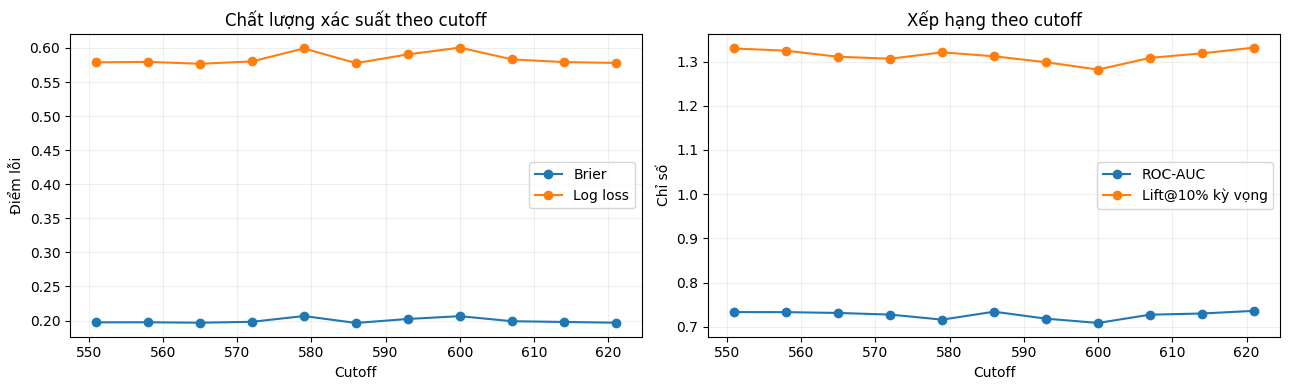

In [4]:
by_cutoff = pd.DataFrame([{'snapshot_day': int(day), **evaluate_baseline(group)}
                          for day, group in validation.groupby('snapshot_day', sort=True)])
display(by_cutoff[['snapshot_day','rows','positive_rate','brier_score','log_loss','roc_auc','lift_at_k_expected']])
fig, axes = plt.subplots(1, 2, figsize=(13,4))
axes[0].plot(by_cutoff.snapshot_day, by_cutoff.brier_score, marker='o', label='Brier')
axes[0].plot(by_cutoff.snapshot_day, by_cutoff.log_loss, marker='o', label='Log loss')
axes[0].set(title='Chất lượng xác suất theo cutoff', xlabel='Cutoff', ylabel='Điểm lỗi'); axes[0].legend()
axes[1].plot(by_cutoff.snapshot_day, by_cutoff.roc_auc, marker='o', label='ROC-AUC')
axes[1].plot(by_cutoff.snapshot_day, by_cutoff.lift_at_k_expected, marker='o', label='Lift@10% kỳ vọng')
axes[1].set(title='Xếp hạng theo cutoff', xlabel='Cutoff', ylabel='Chỉ số'); axes[1].legend()
for ax in axes: ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 5. Đối chiếu dự báo và tỷ lệ thực tế theo nhóm

So sánh xác suất ước lượng từ train với tỷ lệ quan sát ở validation. Bảng chỉ mô tả calibration theo nhóm recency; cùng household có thể xuất hiện nhiều lần và quy mô nhóm khác nhau.

,household_snapshots,unique_households,observed_rate,predicted_probability
recency_group,,,,
0–7,15838,2300,0.708044,0.704739
8–14,3606,1820,0.489462,0.490408
15–30,3231,1310,0.357474,0.351802
31–60,1934,706,0.221820,0.208393
61–90,879,302,0.135381,0.135447
91+,1992,307,0.070281,0.065620


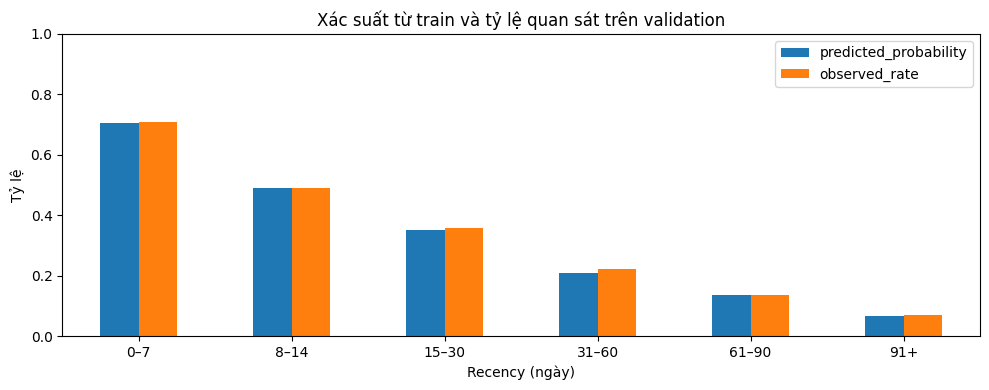

In [5]:
calibration = (validation.groupby('recency_group', observed=False)
               .agg(household_snapshots=(TARGET,'size'), unique_households=('household_key','nunique'),
                    observed_rate=(TARGET,'mean'), predicted_probability=('probability','mean')))
display(calibration)
ax = calibration[['predicted_probability','observed_rate']].plot.bar(figsize=(10,4), rot=0)
ax.set(title='Xác suất từ train và tỷ lệ quan sát trên validation', xlabel='Recency (ngày)', ylabel='Tỷ lệ', ylim=(0,1))
plt.tight_layout(); plt.show()

## 6. Tổng hợp hiệu quả khi chọn household theo từng cutoff

Nếu mỗi tuần có ngân sách tiếp cận bằng 10% số household đủ điều kiện, ta chọn top 10% **riêng trong từng cutoff**; các hộ đồng điểm ở ranh giới được lấy theo tỷ lệ kỳ vọng như mục 3. Bảng so sánh giá trị trung bình không trọng số giữa các cutoff, khoảng min–max và lift của toàn bộ các suất chọn hằng tuần (tổng số lượt mua kỳ vọng chia tổng số suất, rồi chia tỷ lệ mua chung validation).

Một household xuất hiện ở nhiều tuần được tính là nhiều lượt dự báo. Đây là kết quả kỳ vọng trong các nhóm đồng điểm, không phải danh sách hộ cụ thể và không đo tác động tăng thêm do liên hệ.

In [6]:
weekly_totals = by_cutoff.copy()
weekly_totals['expected_positive_top'] = weekly_totals.precision_at_k_expected * weekly_totals.k
weekly_expected_precision = weekly_totals.expected_positive_top.sum() / weekly_totals.k.sum()
weekly_summary = pd.Series({
    'số cutoff': len(weekly_totals),
    'tổng household-snapshot': int(weekly_totals.rows.sum()),
    'tổng suất top 10%': int(weekly_totals.k.sum()),
    'lift trung bình giữa cutoff (không trọng số)': weekly_totals.lift_at_k_expected.mean(),
    'lift thấp nhất theo cutoff': weekly_totals.lift_at_k_expected.min(),
    'lift cao nhất theo cutoff': weekly_totals.lift_at_k_expected.max(),
    'precision kỳ vọng gộp các suất tuần': weekly_expected_precision,
    'lift kỳ vọng gộp các suất tuần': weekly_expected_precision / validation[TARGET].mean(),
    'lift kỳ vọng top 10% gộp mọi cutoff': metrics['lift_at_k_expected'],
}, name='validation')
display(weekly_summary.to_frame())

,validation
số cutoff,11.000000
tổng household-snapshot,27480.000000
tổng suất top 10%,2750.000000
lift trung bình giữa cutoff (không trọng số),1.313018
lift thấp nhất theo cutoff,1.281908
lift cao nhất theo cutoff,1.331582
precision kỳ vọng gộp các suất tuần,0.708168
lift kỳ vọng gộp các suất tuần,1.312945
lift kỳ vọng top 10% gộp mọi cutoff,1.312714


## 7. Baseline hoạt động thế nào theo độ dài lịch sử?

Chia validation thành hai nhóm theo số ngày từ basket đầu tiên được ghi nhận **tính cả ngày đầu**: dưới 180 ngày và từ 180 ngày. Tỷ lệ và chỉ số dưới đây tính trên household-snapshot, kèm số hộ riêng biệt; một hộ có thể xuất hiện trong cả hai nhóm tại các cutoff khác nhau. Mỗi nhóm được tính top 10% của chính nhóm đó, nên lift nhóm không tương đương một danh sách top 10% chung.

In [7]:
validation['history_group'] = np.where(validation.observed_tenure_days + 1 < 180,
                                       'Dưới 180 ngày', 'Từ 180 ngày')
history_metrics = pd.DataFrame([
    {'history_group': name, **evaluate_baseline(frame)}
    for name, frame in validation.groupby('history_group', sort=True)
])
display(history_metrics[['history_group','rows','households','positive_rate','brier_score',
                         'log_loss','roc_auc','lift_at_k_expected','ties_at_threshold']])

,history_group,rows,households,positive_rate,brier_score,log_loss,roc_auc,lift_at_k_expected,ties_at_threshold
0,Dưới 180 ngày,11,2,0.363636,0.295019,0.790431,0.446429,0.687500,4
1,Từ 180 ngày,27469,2498,0.539444,0.199553,0.583991,0.726920,1.312757,15834


**Cách đọc:** Chênh lệch giữa nhóm có thể liên quan đến thành phần household, tần suất mua và nhiều yếu tố khác; không chứng minh tác động của độ dài lịch sử. Khi so sánh với mô hình mới cần giữ cùng phân nhóm, cutoff và quy tắc tính chỉ số.

## 8. Bàn giao

Lưu tỷ lệ train, dự báo validation và các chỉ số để so sánh những mô hình tiếp theo. Không ghi dự báo hay kết quả test. Feature, mô hình và các quyết định tiếp theo cần được chọn trên train/validation; tập test trước đây đã được xem xét nên chỉ là bằng chứng tham khảo cho POC.

In [8]:
OUT.mkdir(parents=True, exist_ok=True)
rates.to_csv(OUT / 'train_recency_rates.csv', encoding='utf-8-sig')
validation[['household_key','snapshot_day','recency_days','recency_group',TARGET,'probability']].to_parquet(
    OUT / 'validation_predictions.parquet', index=False)
by_cutoff.to_csv(OUT / 'validation_metrics_by_cutoff.csv', index=False, encoding='utf-8-sig')
pd.DataFrame([metrics]).to_csv(OUT / 'validation_metrics.csv', index=False, encoding='utf-8-sig')
calibration.to_csv(OUT / 'validation_calibration_by_recency.csv', encoding='utf-8-sig')
weekly_summary.to_csv(OUT / 'validation_weekly_summary.csv', header=True, encoding='utf-8-sig')
history_metrics.to_csv(OUT / 'validation_metrics_by_history.csv', index=False, encoding='utf-8-sig')
print('Đã lưu kết quả baseline tại:', OUT)

Đã lưu kết quả baseline tại: artifacts\baseline_recency
